# Lab 1-03：用 numpy 手寫 attention

**目標**：不靠任何框架，用十幾行 numpy 算出 self-attention，再跟 PyTorch 的版本對答案。

**你會學到**
- Q、K、V 只是三個小矩陣乘法
- 「每個 token 回頭看前面的 token」怎麼變成一張權重表
- 為什麼 context 越長越貴：那張表是 N × N

**前置**：numpy、matplotlib；最後對答案用到 PyTorch（模組 1 的依賴群組已包含）。

**對應投影片**：「RNN 的瓶頸」「attention 直覺」「Q、K、V 小矩陣圖」「Attention 公式逐項拆解」「context 與 O(N²) 成本」

```
輸入向量 X（N × d）
   │
   ├──► Q = X @ Wq ──┐
   ├──► K = X @ Wk ──┴──► 分數 = Q @ K.T / √d（N × N）
   │                         │
   │                         ▼
   │                      因果遮罩：看不到後面的位置設成 -∞
   │                         │
   │                         ▼
   │                      softmax → 權重（每一列加起來是 1）
   │                         │
   └──► V = X @ Wv ──────────┴──► 輸出 = 權重 @ V（N × d）
```

*圖：attention 就是這五步。Q、K 決定「看誰」，V 決定「拿到什麼」；N × N 那張權重表就是 context 越長越貴的原因。*

## Step 1：問題——RNN 只能傳一張小紙條

RNN 讀句子時，把前面所有內容壓進一個固定大小的向量，一路往後傳。句子一長，前面的細節就被擠掉。
attention 的做法是：**每個 token 直接回頭看所有前面的 token，自己決定要看誰多一點**。

## Step 2：準備四個 token 的向量

真實模型的向量來自 embedding 表（上一本的 Step 3）。這裡用隨機數代替，維度設成 8 方便看。

In [1]:
import numpy as np

rng = np.random.default_rng(0)
tokens = ["魯夫", "吃了", "橡膠", "果實"]
N, d = len(tokens), 8
X = rng.normal(size=(N, d))
print("X 形狀：", X.shape, "（token 數 × 維度）")

X 形狀： (4, 8) （token 數 × 維度）


## Step 3：Q、K、V＝三個矩陣乘法

- **Q（query）**：我想找什麼
- **K（key）**：我身上有什麼可以被找
- **V（value）**：被選中時我要交出去的內容

三個權重矩陣是訓練學出來的；這裡一樣用隨機數。

In [2]:
Wq, Wk, Wv = (rng.normal(size=(d, d)) for _ in range(3))
Q, K, V = X @ Wq, X @ Wk, X @ Wv
print(Q.shape, K.shape, V.shape)

(4, 8) (4, 8) (4, 8)


## Step 4：每個 token 對每個 token 打分數

分數＝Q 和 K 的內積。除以 √d 是為了讓數值不要太大，softmax 才不會一面倒。

In [3]:
scores = Q @ K.T / np.sqrt(d)
print(np.round(scores, 1))

[[  0.8  -7.1   0.6  -3.6]
 [ 15.3 -27.4  -6.2   3.1]
 [  1.2   1.9   2.2  -1.3]
 [ -2.2  -0.2  -2.4   0.3]]


## Step 5：不准偷看後面（causal mask）

生成時第 3 個字還不存在，第 2 個字當然不能看它。把右上角設成負無限大，softmax 後就變成 0。

In [4]:
mask = np.triu(np.ones((N, N), dtype=bool), k=1)
scores_masked = np.where(mask, -np.inf, scores)


def softmax(x: np.ndarray) -> np.ndarray:
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


weights = softmax(scores_masked)
print(np.round(weights, 2))
print("每一列加起來：", weights.sum(axis=1))

[[1.   0.   0.   0.  ]
 [1.   0.   0.   0.  ]
 [0.17 0.36 0.47 0.  ]
 [0.05 0.35 0.04 0.56]]
每一列加起來： [1. 1. 1. 1.]


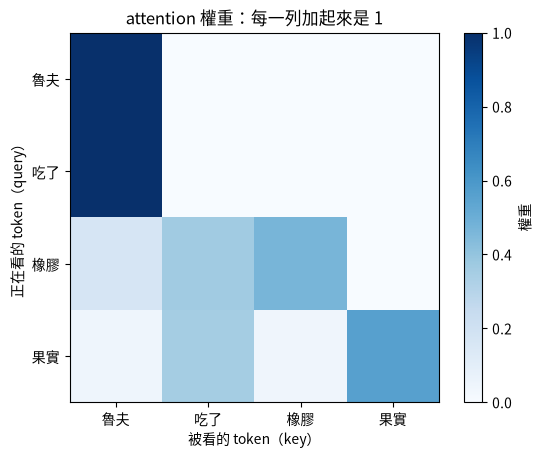

In [5]:
import matplotlib.pyplot as plt
from course_utils.viz import setup_cjk

setup_cjk()
plt.imshow(weights, cmap="Blues")
plt.xticks(range(N), tokens)
plt.yticks(range(N), tokens)
plt.xlabel("被看的 token（key）")
plt.ylabel("正在看的 token（query）")
plt.title("attention 權重：每一列加起來是 1")
plt.colorbar(label="權重")
plt.show()

每一列是一個 token「把注意力分給誰」。第一列只能看自己，所以是 1.0。

## Step 6：按權重把 V 加起來

In [6]:
out = weights @ V
print("輸出形狀：", out.shape, "（跟輸入一樣，每個 token 換成一個新向量）")

輸出形狀： (4, 8) （跟輸入一樣，每個 token 換成一個新向量）


整個 attention 就這四行：

```python
Q, K, V = X @ Wq, X @ Wk, X @ Wv
scores  = Q @ K.T / sqrt(d)      # 加上 causal mask
weights = softmax(scores)
out     = weights @ V
```

## Step 7：跟 PyTorch 對答案

In [7]:
import torch
import torch.nn.functional as F

ref = F.scaled_dot_product_attention(
    torch.tensor(Q)[None], torch.tensor(K)[None], torch.tensor(V)[None], is_causal=True
)[0].numpy()
print("跟 PyTorch 一樣嗎？", np.allclose(out, ref))

跟 PyTorch 一樣嗎？ True


## Step 8：一層 Transformer 的組成

一層＝attention（跟別的 token 交換資訊）＋ MLP（每個 token 自己想一想），各自加回原本的輸入（殘差）。
真實模型還有 LayerNorm 和多頭（multi-head），但骨架就這樣。Qwen2.5-0.5B 疊了 24 層。

In [8]:
W1, W2 = rng.normal(size=(d, 4 * d)) * 0.1, rng.normal(size=(4 * d, d)) * 0.1


def attention(x: np.ndarray) -> np.ndarray:
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    s = np.where(mask, -np.inf, q @ k.T / np.sqrt(d))
    return softmax(s) @ v


def mlp(x: np.ndarray) -> np.ndarray:
    return np.maximum(0, x @ W1) @ W2


def block(x: np.ndarray) -> np.ndarray:
    x = x + attention(x)
    x = x + mlp(x)
    return x


print(block(X).shape)

(4, 8)


## Step 9：為什麼 context 越長越貴

權重表是 N × N。token 數變 2 倍，表就變 4 倍；這就是 O(N²)。

In [9]:
for n in [1_000, 8_000, 32_000, 128_000]:
    mb = n * n * 2 / 1e6  # 每格用 2 byte（fp16），只算一層、一個頭
    print(f"{n:>7} token → 權重表 {mb:>10,.0f} MB")

   1000 token → 權重表          2 MB
   8000 token → 權重表        128 MB
  32000 token → 權重表      2,048 MB
 128000 token → 權重表     32,768 MB


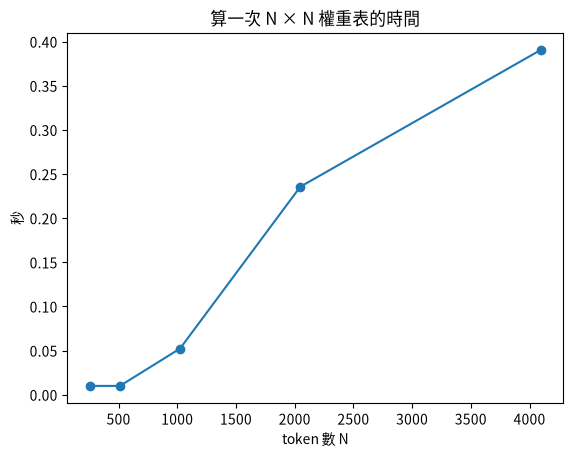

In [10]:
import time

ns, secs = [256, 512, 1024, 2048, 4096], []
for n in ns:
    q = rng.normal(size=(n, 64)).astype(np.float32)
    t = time.perf_counter()
    softmax(q @ q.T)
    secs.append(time.perf_counter() - t)

plt.plot(ns, secs, marker="o")
plt.xlabel("token 數 N")
plt.ylabel("秒")
plt.title("算一次 N × N 權重表的時間")
plt.show()

曲線往上彎，不是直線。實務後果：塞一大堆文件進 context 不只貴，還慢；而且模型容易漏看中間的內容。
這也是為什麼要做 RAG：只放最相關的幾段進去。

## 試試看

1. 拿掉 Step 5 的 mask，權重表長什麼樣？這種「雙向」attention 是 BERT 用的。
2. 把 Step 4 的 `/ np.sqrt(d)` 拿掉、把 `d` 改成 512，看 softmax 是不是變得一面倒。
3. 把 Step 9 的 `n` 加到 8192，時間大約變幾倍？

## 小結

- attention＝Q、K 打分數 → softmax 成權重 → 按權重加總 V。
- causal mask 讓模型只能看前面，所以能一個字一個字生成。
- 權重表是 N × N，context 越長成本越高。下一本：不碰模型內部，直接用 API 跟它對話。